# MELD sentiment and emotion

Run All recalculates the results from the recorded transcripts, labels and model predictions embedded here. Run from the folder containing this notebook. Set `REBUILD_MODELS = True` to regenerate predictions from the audio and pretrained models instead. That mode needs internet access and CUDA PyTorch.

[MELD](https://aclanthology.org/P19-1050/) · [emotion2vec](https://aclanthology.org/2024.findings-acl.931/) · [MERITS-L](https://arxiv.org/abs/2501.11468)

In [1]:
import importlib.util
import subprocess
import sys
from pathlib import Path

REBUILD_MODELS = False

dependencies = {
    'numpy': 'numpy==2.5.3',
    'pandas': 'pandas==3.0.6',
    'sklearn': 'scikit-learn==1.9.1',
    'matplotlib': 'matplotlib==3.11.2',
    'jiwer': 'jiwer==4.0.0',
    'threadpoolctl': 'threadpoolctl',
}
if REBUILD_MODELS:
    dependencies.update({
        'soundfile': 'soundfile==0.14.0',
        'transformers': 'transformers==5.19.0',
        'funasr': 'funasr==1.4.16',
        'faster_whisper': 'faster-whisper==1.2.1',
    })
missing = [package for module, package in dependencies.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])

In [2]:
import base64
import io
import json
import tempfile
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

if REBUILD_MODELS:
    root = Path.cwd() / 'meld_rebuild'
    root.mkdir(exist_ok=True)
else:
    for notebook_path in sorted(Path.cwd().glob('*.ipynb')):
        notebook = json.loads(notebook_path.read_text(encoding='utf-8'))
        snapshot = notebook.get('metadata', {}).get('meld_recorded_inputs')
        if snapshot:
            break
    else:
        raise FileNotFoundError('Open and run this notebook from the folder containing the .ipynb file.')
    replay = tempfile.TemporaryDirectory(prefix='meld_')
    root = Path(replay.name)
    with zipfile.ZipFile(io.BytesIO(base64.b64decode(snapshot))) as bundle:
        bundle.extractall(root)
    del snapshot, notebook
out = root / 'outputs'


SENTIMENTS = ["negative", "neutral", "positive"]
EMOTIONS = ["anger", "disgust", "fear", "joy", "neutral", "sadness", "surprise"]
SEED = 42


def load_rows(root: Path, split: str) -> pd.DataFrame:
    frame = pd.read_csv(root / "data" / "MELD" / f"{split}.csv")
    frame["uid"] = "dia" + frame.Dialogue_ID.astype(str) + "_utt" + frame.Utterance_ID.astype(str)
    if frame.uid.duplicated().any(): raise ValueError(f"Duplicate official IDs in {split} CSV")
    cache_path = root / "outputs" / f"asr_{split}.json"
    if not cache_path.exists():
        raise FileNotFoundError(f"Required existing transcript cache is missing: {cache_path}")
    cache = json.loads(cache_path.read_text(encoding="utf-8"))
    frame["asr"] = frame.uid.map(cache)
    frame["Utterance"] = frame.Utterance.fillna("").astype(str).str.replace("\x92", "'", regex=False).str.replace("\x97", " ", regex=False)
    frame = frame[frame.asr.notna()].copy()
    frame["asr"] = frame.asr.fillna("").astype(str)
    frame["sent_y"] = frame.Sentiment.map({v: i for i, v in enumerate(SENTIMENTS)})
    frame["emo_y"] = frame.Emotion.map({v: i for i, v in enumerate(EMOTIONS)})
    if frame[["sent_y", "emo_y"]].isna().any().any():
        raise ValueError(f"Unexpected labels in {split} CSV")
    if frame.uid.duplicated().any() or frame.asr.isna().any(): raise ValueError(f"ID/cache alignment failed for {split}")
    return frame.reset_index(drop=True)


def make_contexts(frame: pd.DataFrame, current_only: bool = False) -> list[dict[str, str]]:
    frame = frame.reset_index(drop=True)
    result: list[dict[str, str]] = [{} for _ in range(len(frame))]
    for _, group in frame.groupby("Dialogue_ID", sort=False):
        group = group.sort_values("Utterance_ID")
        speakers = {speaker: i + 1 for i, speaker in enumerate(group.Speaker.drop_duplicates())}
        records = list(group.iterrows())
        for pos, (index, row) in enumerate(records):
            if current_only:
                result[index] = {"gold": row.Utterance, "asr": row.asr}
                continue

            selected = [records[pos]] + records[max(0, pos - 3):pos] + records[pos + 1:pos + 3]
            target_offset = 0
            result[index] = {
                "gold": " </s> ".join(f"<{('TARGET' if j == target_offset else 'OTHER')}_S{speakers[t.Speaker]}> {t.Utterance}" for j, (_, t) in enumerate(selected)),
                "asr": " </s> ".join(f"<{('TARGET' if j == target_offset else 'OTHER')}_S{speakers[t.Speaker]}> {t.asr}" for j, (_, t) in enumerate(selected)),
            }
    return result

## Model rebuild

In [3]:
if REBUILD_MODELS:
    import torch
    if not (torch.cuda.is_available() and torch.cuda.is_bf16_supported()):
        raise RuntimeError('Model rebuild requires CUDA PyTorch and a GPU with BF16 support.')
    import os, gc, json, time, random
    from pathlib import Path
    import numpy as np, pandas as pd, soundfile as sf
    import torch
    from threadpoolctl import threadpool_limits
    threadpool_limits(limits=4)
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import StandardScaler
    from sklearn.metrics import f1_score
    import logging
    logging.getLogger('httpx').setLevel(logging.WARNING)
    if os.name == 'nt':
        torch_lib = os.path.join(os.path.dirname(torch.__file__), 'lib')
        os.add_dll_directory(torch_lib)
        os.environ['PATH'] = torch_lib + os.pathsep + os.environ['PATH']
    SEED = 42
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
    ROOT = root
    DATA = ROOT / 'data' / 'MELD'
    OUT = ROOT / 'outputs'
    OUT.mkdir(exist_ok=True)
    print('device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')
    RETRAIN_TEXT = False


    import urllib.request, tarfile
    HF = 'https://huggingface.co/datasets/ajyy/MELD_audio/resolve/main/'
    (DATA / 'archive').mkdir(parents=True, exist_ok=True)
    for split in ['train', 'dev', 'test']:
        csv = DATA / f'{split}.csv'
        if not csv.exists():
            urllib.request.urlretrieve(HF + f'{split}.csv', csv)
        if not (DATA / split).exists():
            tgz = DATA / 'archive' / f'{split}.tar.gz'
            if not tgz.exists():
                print('downloading', tgz.name)
                urllib.request.urlretrieve(HF + f'archive/{split}.tar.gz', tgz)
            with tarfile.open(tgz) as t:
                t.extractall(DATA, filter='data')

    def load_split(split):
        df = pd.read_csv(DATA / f'{split}.csv')
        df['split'] = split
        df['uid'] = 'dia' + df.Dialogue_ID.astype(str) + '_utt' + df.Utterance_ID.astype(str)
        df['path'] = df.uid.map(lambda u: str(DATA / split / f'{u}.flac'))
        df = df[df.path.map(os.path.exists)].reset_index(drop=True)
        df['Utterance'] = df.Utterance.str.replace('\x92', "'", regex=False).str.replace('\x97', ' ', regex=False)
        df['sent_y'] = df.Sentiment.map(SENTIMENTS.index)
        df['emo_y'] = df.Emotion.map(EMOTIONS.index)
        return df

    train = load_split('train')
    dev = load_split('dev')
    test = load_split('test')
    print({'train': len(train), 'dev': len(dev), 'test': len(test)})

    def load_audio(path):
        a, sr = sf.read(path, dtype='float32')
        if a.ndim > 1:
            a = a.mean(1)
        assert sr == 16000, sr
        return a

    ASR_MODEL = 'large-v3-turbo'

    def add_transcripts(df, name):
        cache = OUT / f'asr_{name}.json'
        transcripts = json.loads(cache.read_text(encoding='utf-8')) if cache.exists() else {}
        missing = df[~df.uid.isin(transcripts)]
        if len(missing):
            from faster_whisper import WhisperModel
            asr_model = WhisperModel(ASR_MODEL, device=DEVICE, compute_type='float16' if DEVICE == 'cuda' else 'int8')
            for i, row in enumerate(missing.itertuples(), 1):
                segments, _ = asr_model.transcribe(load_audio(row.path), language='en', beam_size=5)
                transcripts[row.uid] = ' '.join((segment.text.strip() for segment in segments))
                if i % 100 == 0 or i == len(missing):
                    temporary_cache = cache.with_suffix('.tmp')
                    temporary_cache.write_text(json.dumps(transcripts, ensure_ascii=False), encoding='utf-8')
                    temporary_cache.replace(cache)
                    print(f'{name}: transcribed {i:,}/{len(missing):,} missing clips')
            del asr_model
            torch.cuda.empty_cache()
        df['asr'] = df.uid.map(transcripts)
        assert df.asr.notna().all()

    for df, name in [(train, 'train'), (dev, 'dev'), (test, 'test')]:
        add_transcripts(df, name)

In [4]:
if REBUILD_MODELS:
    E2V_TO_MELD = {0: 'anger', 1: 'disgust', 2: 'fear', 3: 'joy', 4: 'neutral', 6: 'sadness', 7: 'surprise'}

    def e2v_features(df, name):
        cache = OUT / f'e2v_{name}.npz'
        store = {}
        if cache.exists():
            z = np.load(cache, allow_pickle=True)
            store = {u: (e, p) for u, e, p in zip(z['uid'], z['emb'], z['prob'])}
        todo = [(u, p) for u, p in zip(df.uid, df.path) if u not in store]
        if todo:
            from funasr import AutoModel
            e2v = AutoModel(model='emotion2vec/emotion2vec_plus_large', hub='hf', disable_update=True, device=DEVICE)
            MAX_SEC, t = (30, time.time())
            for i in range(0, len(todo), 32):
                chunk = todo[i:i + 32]
                res = e2v.generate([load_audio(p)[:MAX_SEC * 16000] for _, p in chunk], granularity='utterance', extract_embedding=True, disable_pbar=True)
                for (u, _), r in zip(chunk, res):
                    s = np.array(r['scores'])
                    pr = np.array([s[k] for k in E2V_TO_MELD])
                    store[u] = (r['feats'].astype(np.float32), (pr / max(pr.sum(), 1e-08)).astype(np.float32))
            print(f'{name}: {len(todo)} clips encoded in {time.time() - t:.0f}s')
            uids = list(store)
            np.savez(cache, uid=np.array(uids), emb=np.stack([store[u][0] for u in uids]), prob=np.stack([store[u][1] for u in uids]))
            del e2v
            gc.collect()
            torch.cuda.empty_cache()
        return (np.stack([store[u][0] for u in df.uid]), np.stack([store[u][1] for u in df.uid]))
    S = {n: e2v_features(d, n) for n, d in [('train', train), ('dev', dev), ('test', test)]}
    print({k: v[0].shape for k, v in S.items()})

    scaler = StandardScaler().fit(S['train'][0])
    speech_heads = {}
    for task, ycol in [('sent', 'sent_y'), ('emo', 'emo_y')]:
        candidates, scores = ([], [])
        for c_value in [0.1, 0.5, 1.0]:
            clf = LogisticRegression(max_iter=1000, C=c_value, class_weight='balanced', random_state=SEED)
            clf.fit(scaler.transform(S['train'][0]), train[ycol])
            pred = clf.predict(scaler.transform(S['dev'][0]))
            score = f1_score(dev[ycol], pred, labels=np.arange(len(clf.classes_)), average='macro', zero_division=0)
            candidates.append(clf)
            scores.append({'C': c_value, 'dev_macro_f1': float(score)})
        best_i = max(range(len(scores)), key=lambda i: (scores[i]['dev_macro_f1'], -scores[i]['C']))
        speech_heads[task] = candidates[best_i]
    P = {}
    for n in ['dev', 'test']:
        features = scaler.transform(S[n][0])
        for task in ['sent', 'emo']:
            P['speech', n, task] = speech_heads[task].predict_proba(features)

In [5]:
if REBUILD_MODELS:
    from transformers import AutoTokenizer, AutoModel
    from sklearn.utils.class_weight import compute_class_weight
    TXT_MODEL, MAXLEN, BS, EPOCHS, LR = ('roberta-base', 64, 32, 3, 2e-05)
    tok = AutoTokenizer.from_pretrained(TXT_MODEL)

    class TextClassifier(torch.nn.Module):

        def __init__(self):
            super().__init__()
            self.enc = AutoModel.from_pretrained(TXT_MODEL)
            h = self.enc.config.hidden_size
            self.drop = torch.nn.Dropout(0.1)
            self.sent, self.emo = (torch.nn.Linear(h, 3), torch.nn.Linear(h, 7))

        def forward(self, **x):
            cls = self.drop(self.enc(**x).last_hidden_state[:, 0])
            return (self.sent(cls), self.emo(cls))

    def batches(texts, ys=None, shuffle=False):
        idx = np.random.permutation(len(texts)) if shuffle else np.arange(len(texts))
        for i in range(0, len(idx), BS):
            b = idx[i:i + BS]
            enc = tok([texts[j] for j in b], padding=True, truncation=True, max_length=MAXLEN, return_tensors='pt').to(DEVICE)
            yield (enc, None if ys is None else [torch.tensor(y[b], device=DEVICE) for y in ys])

    @torch.no_grad()
    def predict_text(model, texts):
        model.eval()
        ps, pe = ([], [])
        for enc, _ in batches(list(texts)):
            with torch.autocast(DEVICE, dtype=torch.float16, enabled=DEVICE == 'cuda'):
                ls, le = model(**enc)
            ps.append(ls.float().softmax(-1).cpu().numpy())
            pe.append(le.float().softmax(-1).cpu().numpy())
        return (np.concatenate(ps), np.concatenate(pe))

    def train_text(model, texts, checkpoint, history_file, dev_texts=None):
        if dev_texts is None:
            dev_texts = dev.asr.replace('', '...')
        cw = lambda y, k: torch.tensor(np.sqrt(compute_class_weight('balanced', classes=np.arange(k), y=y)), dtype=torch.float, device=DEVICE)
        loss_s, loss_e = (torch.nn.CrossEntropyLoss(weight=cw(train.sent_y, 3)), torch.nn.CrossEntropyLoss(weight=cw(train.emo_y, 7)))
        opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
        total = EPOCHS * int(np.ceil(len(train) / BS))
        warm = int(0.1 * total)
        sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min((s + 1) / warm, max(0.0, (total - s) / (total - warm))))
        scaler_amp = torch.amp.GradScaler(enabled=DEVICE == 'cuda')
        ys = [train.sent_y.values, train.emo_y.values]
        best = -1
        history = []
        temporary_checkpoint = checkpoint.with_suffix('.tmp')
        for ep in range(EPOCHS):
            model.train()
            t = time.time()
            for enc, (ysent, yemo) in batches(texts, ys, shuffle=True):
                with torch.autocast(DEVICE, dtype=torch.float16, enabled=DEVICE == 'cuda'):
                    ls, le = model(**enc)
                    loss = loss_s(ls.float(), ysent) + loss_e(le.float(), yemo)
                opt.zero_grad()
                scaler_amp.scale(loss).backward()
                scaler_amp.step(opt)
                scaler_amp.update()
                sched.step()
            ps, pe = predict_text(model, dev_texts)
            sentiment_f1 = f1_score(dev.sent_y, ps.argmax(1), labels=range(3), average='macro', zero_division=0)
            emotion_f1 = f1_score(dev.emo_y, pe.argmax(1), labels=range(7), average='macro', zero_division=0)
            f1 = (sentiment_f1 + emotion_f1) / 2
            history.append({'epoch': ep + 1, 'sentiment_macro_f1': sentiment_f1, 'emotion_macro_f1': emotion_f1, 'mean_macro_f1': f1})
            print(f'epoch {ep + 1}: dev mean macro-F1 = {f1:.4f}  ({time.time() - t:.0f}s)')
            if f1 > best:
                best = f1
                torch.save(model.state_dict(), temporary_checkpoint)
        temporary_checkpoint.replace(checkpoint)
        pd.DataFrame(history).to_csv(history_file, index=False)

    ckpt = OUT / 'roberta_meld_balanced.pt'
    model = TextClassifier().to(DEVICE)
    if not ckpt.exists() or RETRAIN_TEXT:
        train_text(model, list(train.Utterance), ckpt, OUT / 'training_history.csv')
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE, weights_only=True))
    for n, df in [('dev', dev), ('test', test)]:
        for src, col in [('text_gold', 'Utterance'), ('text_asr', 'asr')]:
            P[src, n, 'sent'], P[src, n, 'emo'] = predict_text(model, df[col].replace('', '...'))
    del model
    gc.collect()
    torch.cuda.empty_cache()

    for task, column in [('sent', 'sent_y'), ('emo', 'emo_y')]:
        text, audio = P['text_asr', 'dev', task], P['speech', 'dev', task]
        classes = np.arange(text.shape[1])
        scores = []
        for weight in np.linspace(0, 1, 21):
            prediction = (weight * text + (1 - weight) * audio).argmax(1)
            score = f1_score(dev[column], prediction, labels=classes, average='macro', zero_division=0)
            scores.append((score, float(weight)))
        weight = max(scores, key=lambda item: (item[0], -abs(item[1] - 0.5)))[1]
        for split in ['dev', 'test']:
            text, audio = P['text_asr', split, task], P['speech', split, task]
            P['fuse_avg', split, task] = weight * text + (1 - weight) * audio

    for split, frame in [('dev', dev), ('test', test)]:
        predictions = frame[['uid', 'Dialogue_ID', 'Utterance_ID', 'Sentiment', 'Emotion']].copy()
        for model in ['text_gold', 'text_asr', 'speech', 'fuse_avg']:
            for task, names in [('sent', SENTIMENTS), ('emo', EMOTIONS)]:
                probabilities = P[model, split, task]
                for i, name in enumerate(names):
                    predictions[f'{model}_{task}_prob_{name}'] = probabilities[:, i]
        predictions.to_csv(OUT / f'predictions_{split}.csv', index=False)
        print(f'Saved {len(predictions)} {split} baseline predictions')

In [6]:
if REBUILD_MODELS:
    from torch.utils.data import DataLoader, Dataset

    class EncodedRows(Dataset):
        def __init__(self, contexts, labels, tokenizer, mode, max_len):
            self.labels, self.mode = labels, mode
            self.encoded = {source: tokenizer([row[source] for row in contexts], truncation=True, max_length=max_len) for source in ("gold", "asr")}

        def __len__(self):
            return len(self.labels)

        def __getitem__(self, i):
            return i, self.labels[i]

        def features(self, source, index):

            return {key: values[index] for key, values in self.encoded[source].items()}


    class ContextClassifier(torch.nn.Module):
        def __init__(self, model_name: str):
            super().__init__()
            self.encoder = AutoModel.from_pretrained(model_name)
            hidden = self.encoder.config.hidden_size
            self.dropout = torch.nn.Dropout(0.1)
            self.sentiment = torch.nn.Linear(hidden, 3)
            self.emotion = torch.nn.Linear(hidden, 7)

        def forward(self, **inputs):
            pooled = self.dropout(self.encoder(**inputs).last_hidden_state[:, 0])
            return self.sentiment(pooled), self.emotion(pooled)


    def _collator(tokenizer, encoded, training=False, epoch=0, source="gold"):
        def collate(batch):
            indices = [item[0] for item in batch]
            batch_source = source
            if training and encoded.mode == "mixed":
                batch_source = None
            if batch_source is None:

                sources = ["gold" if (i + epoch) % 2 == 0 else "asr" for i in indices]
                inputs = [encoded.features(s, i) for s, i in zip(sources, indices)]
                batch_inputs = tokenizer.pad(inputs, padding=True, return_tensors="pt")
            else:
                batch_inputs = tokenizer.pad([encoded.features(batch_source, i) for i in indices], padding=True, return_tensors="pt")
            labels = torch.tensor([encoded.labels[i] for i in indices], dtype=torch.long)
            return batch_inputs, labels
        return collate


    def _probabilities(model, dataset, tokenizer, source, device, batch_size):
        model.eval()
        precision = amp_dtype(model, device)
        results = []
        collate = _collator(tokenizer, dataset, training=False, source=source)
        loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, collate_fn=collate)
        with torch.no_grad():
            for inputs, _ in loader:
                inputs = {k: v.to(device) for k, v in inputs.items()}
                with torch.autocast(device_type="cuda", dtype=precision, enabled=device.type == "cuda"):
                    sent, emo = model(**inputs)
                results.append((sent.float().softmax(-1).cpu().numpy(), emo.float().softmax(-1).cpu().numpy()))
        return np.concatenate([p[0] for p in results]), np.concatenate([p[1] for p in results])


    def amp_dtype(model, device):
        if device.type == "cuda" and model.encoder.config.hidden_size >= 1024 and torch.cuda.is_bf16_supported():
            return torch.bfloat16
        return torch.float16


    def save_predictions(frame, probabilities, split, transcript, out, model_tag):
        sent, emo = probabilities
        result = frame[["uid", "Dialogue_ID", "Utterance_ID", "Sentiment", "Emotion"]].copy()
        result.insert(0, "split", split)
        result.insert(1, "transcript_source", transcript)
        result["pred_sentiment"] = [SENTIMENTS[i] for i in sent.argmax(1)]
        result["pred_emotion"] = [EMOTIONS[i] for i in emo.argmax(1)]
        for i, label in enumerate(SENTIMENTS): result[f"sentiment_p_{label}"] = sent[:, i]
        for i, label in enumerate(EMOTIONS): result[f"emotion_p_{label}"] = emo[:, i]
        result.to_csv(out / f"predictions_{model_tag}_{split}_{transcript}.csv", index=False)


    def train(root: str | Path = ".", model_name="roberta-base", mode="mixed", epochs=5, batch_size=16, max_len=128, lr=2e-5, current_only=False):
        if mode not in {"gold", "mixed"}: raise ValueError("mode must be gold or mixed")
        root, out = Path(root), Path(root) / "outputs"
        out.mkdir(exist_ok=True)
        random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_df, dev_df = load_rows(root, "train"), load_rows(root, "dev")
        tok = AutoTokenizer.from_pretrained(model_name)
        contexts = {name: make_contexts(df, current_only=current_only) for name, df in [("train", train_df), ("dev", dev_df)]}
        labels = {name: list(zip(df.sent_y.astype(int), df.emo_y.astype(int))) for name, df in [("train", train_df), ("dev", dev_df)]}
        data = {name: EncodedRows(contexts[name], labels[name], tok, mode, max_len) for name in contexts}
        model = ContextClassifier(model_name).to(device)
        if device.type == "cuda" and model.encoder.config.hidden_size >= 1024:
            model.encoder.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
        sy, ey = train_df.sent_y.to_numpy(), train_df.emo_y.to_numpy()
        w_s = torch.tensor(np.sqrt(compute_class_weight("balanced", classes=np.arange(3), y=sy)), dtype=torch.float32, device=device)
        w_e = torch.tensor(np.sqrt(compute_class_weight("balanced", classes=np.arange(7), y=ey)), dtype=torch.float32, device=device)
        loss_s, loss_e = torch.nn.CrossEntropyLoss(weight=w_s), torch.nn.CrossEntropyLoss(weight=w_e)
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01, foreach=False)
        steps = epochs * int(np.ceil(len(data["train"]) / batch_size))
        warm_steps = max(1, int(0.1 * steps))
        scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda step: min((step + 1) / warm_steps, max(0.0, (steps - step) / max(1, steps - warm_steps))))
        precision = amp_dtype(model, device)
        amp = torch.amp.GradScaler("cuda", enabled=device.type == "cuda" and precision == torch.float16)
        history, best = [], -1.0
        tag = f"context_{mode}_{Path(model_name).name}" + ("_current" if current_only else "")
        checkpoint = out / f"{tag}.pt"
        for epoch in range(epochs):
            model.train()
            updates = 0
            loader = DataLoader(data["train"], batch_size=batch_size, shuffle=True, generator=torch.Generator().manual_seed(SEED + epoch), collate_fn=_collator(tok, data["train"], True, epoch))
            for step, (inputs, ys) in enumerate(loader, 1):
                inputs = {k: v.to(device) for k, v in inputs.items()}; ys = ys.to(device)
                with torch.autocast(device_type="cuda", dtype=precision, enabled=device.type == "cuda"):
                    ps, pe = model(**inputs)
                    loss = loss_s(ps.float(), ys[:, 0]) + loss_e(pe.float(), ys[:, 1])
                optimizer.zero_grad(set_to_none=True)
                amp.scale(loss).backward()
                if precision == torch.bfloat16:
                    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0, error_if_nonfinite=True)
                scale_before = amp.get_scale(); amp.step(optimizer); amp.update()
                if amp.get_scale() >= scale_before:
                    scheduler.step()
                    updates += 1
                if step == 128 and updates == 0:
                    raise RuntimeError("Mixed precision skipped the first 128 updates. Training is unstable.")
            sources = ["gold", "asr"] if mode == "mixed" else ["gold"]
            metrics = {}
            for source in sources:
                probs = _probabilities(model, data["dev"], tok, source, device, batch_size)
                sf = f1_score(dev_df.sent_y, probs[0].argmax(1), labels=range(3), average="macro", zero_division=0)
                ef = f1_score(dev_df.emo_y, probs[1].argmax(1), labels=range(7), average="weighted", zero_division=0)
                metrics[source] = (float(sf), float(ef))
            sf = float(np.mean([v[0] for v in metrics.values()])); ef = float(np.mean([v[1] for v in metrics.values()]))
            row = {"epoch": epoch + 1, "optimizer_updates": updates, "dev_sentiment_macro_f1": sf, "dev_emotion_weighted_f1": ef, "selection_score": float((sf + ef) / 2)}
            for source, values in metrics.items():
                row[f"dev_{source}_sentiment_macro_f1"], row[f"dev_{source}_emotion_weighted_f1"] = values
            history.append(row); print(row)
            if row["selection_score"] > best:
                best = row["selection_score"]
                temporary = checkpoint.with_suffix(".tmp")
                torch.save({"state_dict": model.state_dict(), "model_name": model_name, "mode": mode, "max_len": max_len, "seed": SEED, "current_only": current_only}, temporary)
                temporary.replace(checkpoint)
        pd.DataFrame(history).to_csv(out / f"{tag}_history.csv", index=False)
        del optimizer, scheduler, amp
        model.zero_grad(set_to_none=True)
        if device.type == "cuda":
            torch.cuda.empty_cache()
        saved = torch.load(checkpoint, map_location="cpu", weights_only=True)
        model.load_state_dict(saved["state_dict"])
        del saved
        test_df = load_rows(root, "test")
        contexts["test"] = make_contexts(test_df, current_only=current_only)
        labels["test"] = list(zip(test_df.sent_y.astype(int), test_df.emo_y.astype(int)))
        data["test"] = EncodedRows(contexts["test"], labels["test"], tok, mode, max_len)
        for split, df in [("dev", dev_df), ("test", test_df)]:
            sources = ["gold", "asr"] if mode == "mixed" else ["gold"]
            for source in sources:
                chosen = contexts[split] if source == "gold" else [{"gold": c["asr"], "asr": c["asr"]} for c in contexts[split]]
                eval_data = EncodedRows(chosen, labels[split], tok, "gold", max_len)
                if len(df) != len(eval_data) or len(df.uid.unique()) != len(df): raise ValueError(f"Prediction IDs misaligned for {split}")
                save_predictions(df, _probabilities(model, eval_data, tok, "gold", device, batch_size), split, source, out, tag)
        return checkpoint





    trials = [
        ('roberta-base', 'gold', 5, 16, 2e-5, False),
        ('roberta-base', 'mixed', 5, 16, 2e-5, False),
        ('roberta-base', 'mixed', 5, 16, 2e-5, True),
        ('SamLowe/roberta-base-go_emotions', 'mixed', 5, 16, 2e-5, False),
        ('FacebookAI/roberta-large', 'mixed', 3, 8, 1e-5, False),
    ]
    for model_name, mode, epochs, batch_size, learning_rate, current_only in trials:
        tag = f"context_{mode}_{Path(model_name).name}" + ("_current" if current_only else "")
        sources = ['gold', 'asr'] if mode == 'mixed' else ['gold']
        expected = [out / f'predictions_{tag}_{split}_{source}.csv'
                    for split in ['dev', 'test'] for source in sources]
        if not all(path.is_file() for path in expected):
            train(root, model_name, mode, epochs, batch_size, lr=learning_rate, current_only=current_only)

## Evaluation

In [7]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


def _check_columns(frame, *columns):
    missing = [column for column in columns if column not in frame.columns]
    if missing:
        raise ValueError(f"Missing required column(s): {', '.join(missing)}")


def _labels(frame, column, speaker_col="Speaker"):
    result = {}
    for speaker, group in frame.groupby(speaker_col, sort=False, dropna=True):
        labels = []
        for value in group[column]:
            if pd.isna(value) or not str(value).strip():
                continue
            value = str(value).strip()
            if not labels or labels[-1] != value:
                labels.append(value)
        if labels:
            result[speaker] = labels
    return result


def summarize_dialogue(frame, text_col, emotion_col, speaker_col="Speaker",
                       order_col="Utterance_ID"):
    _check_columns(frame, speaker_col, order_col, text_col, emotion_col)
    ordered = frame.sort_values(order_col, kind="stable", na_position="last")
    valid = ordered[ordered[text_col].notna()].copy()
    valid[text_col] = valid[text_col].map(str)
    valid = valid[valid[text_col].str.strip().ne("")]
    quotes = []
    if not valid.empty:
        try:
            matrix = TfidfVectorizer(stop_words="english").fit_transform(valid[text_col])
            center = np.asarray(matrix.mean(axis=0))
            relevance, redundancy = cosine_similarity(matrix, center).ravel(), cosine_similarity(matrix)
        except ValueError:
            relevance, redundancy = np.zeros(len(valid)), np.zeros((len(valid), len(valid)))
        remaining, chosen = list(range(len(valid))), []
        for _ in range(min(3, len(remaining))):
            scores = [(relevance[i] - 0.35 * max((redundancy[i, j] for j in chosen), default=0), -i, i)
                      for i in remaining]
            selected = max(scores)[2]
            chosen.append(selected)
            remaining.remove(selected)
        for i in sorted(chosen):
            row = valid.iloc[i]
            quotes.append({"speaker": row[speaker_col], "utterance_id": row[order_col],
                           "text": row[text_col]})
    trajectories = _labels(ordered, emotion_col, speaker_col)
    return {"quotes": quotes, "trajectories": trajectories}


def evaluate_trajectories(frame, predicted_col, human_col, speaker_col="Speaker",
                          order_col="Utterance_ID"):
    _check_columns(frame, speaker_col, order_col, predicted_col, human_col)
    ordered = frame.sort_values(order_col, kind="stable", na_position="last")
    per_speaker = {}
    for speaker, group in ordered.groupby(speaker_col, sort=False, dropna=True):
        predicted = _labels(group, predicted_col, speaker_col).get(speaker, [])
        human = _labels(group, human_col, speaker_col).get(speaker, [])
        if not predicted or not human:
            continue
        row = [0] * (len(human) + 1)
        for p in predicted:
            next_row = [0]
            for j, h in enumerate(human, 1):
                next_row.append(row[j - 1] + 1 if p == h else max(row[j], next_row[-1]))
            row = next_row
        per_speaker[speaker] = row[-1] / max(len(predicted), len(human))
    return {"similarity": float(np.mean(list(per_speaker.values()))) if per_speaker else None,
            "per_speaker": per_speaker}


"""Select and score the final MELD classifiers using saved predictions."""

import json
import re
from pathlib import Path

import jiwer
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, f1_score
from threadpoolctl import threadpool_limits



TASKS = [
    ("sentiment", "sent", "Sentiment", SENTIMENTS),
    ("emotion", "emo", "Emotion", EMOTIONS),
]
TEXT_TRIALS = [
    "context_gold_roberta-base",
    "context_mixed_roberta-base",
    "context_mixed_roberta-base_current",
    "context_mixed_roberta-base-go_emotions",
    "context_mixed_roberta-large",
]


def aligned_csv(path, rows):
    predictions = pd.read_csv(path).set_index("uid")
    if not predictions.index.is_unique:
        raise ValueError(f"Duplicate utterance IDs in {path.name}")
    if set(predictions.index) != set(rows.uid):
        raise ValueError(f"Utterance IDs do not match in {path.name}")
    predictions = predictions.loc[rows.uid]
    for column in ["Sentiment", "Emotion"]:
        if not np.array_equal(predictions[column], rows[column]):
            raise ValueError(f"{column} labels do not match in {path.name}")
    return predictions


def metrics(truth, probabilities, labels):
    predicted = probabilities.argmax(axis=1)
    return {
        "accuracy": 100 * accuracy_score(truth, predicted),
        "macro_f1": 100 * f1_score(truth, predicted, labels=range(len(labels)), average="macro", zero_division=0),
        "weighted_f1": 100 * f1_score(truth, predicted, labels=range(len(labels)), average="weighted", zero_division=0),
    }


def normalize_transcript(text):
    return re.sub(r"[^a-z0-9' ]", " ", text.lower())


def evaluate(root="."):
    root = Path(root)
    out = root / "outputs"
    rows = {split: load_rows(root, split) for split in ["train", "dev", "test"]}
    if [len(rows[split]) for split in ["train", "dev", "test"]] != [9988, 1108, 2610]:
        raise ValueError("The final evaluation requires all available official MELD rows")
    old = {split: aligned_csv(out / f"predictions_{split}.csv", rows[split]) for split in ["dev", "test"]}
    truth = {(split, task): frame[column].map(labels.index).to_numpy()
             for split, frame in rows.items() for task, _, column, labels in TASKS}
    results, classes, development, prediction_rows, trajectories = [], [], [], [], []
    settings = {
        "description": "RoBERTa sees the target utterance and up to five nearby turns, with dialogue-local speaker markers.",
        "whisper_test_wer": round(100 * jiwer.wer(
            rows["test"].Utterance.map(normalize_transcript).tolist(),
            rows["test"].asr.map(normalize_transcript).tolist(),
        ), 2),
        "selected_models": {}, "weights": {},
    }
    examples = {}
    for input_name, transcript, column, old_key in [
        ("human", "gold", "Utterance", "text_gold"), ("whisper", "asr", "asr", "text_asr"),
    ]:
        vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
        train_words = vectorizer.fit_transform(rows["train"][column])
        with threadpool_limits(limits=4):
            tfidf = {
                task: LogisticRegression(max_iter=1000, class_weight="balanced").fit(train_words, truth["train", task])
                for task, _, _, _ in TASKS
            }
        words = {split: vectorizer.transform(rows[split][column]) for split in ["dev", "test"]}
        candidates = {"Utterance RoBERTa": old["dev"]}
        for name in TEXT_TRIALS:
            path = out / f"predictions_{name}_dev_{transcript}.csv"
            test_path = out / f"predictions_{name}_test_{transcript}.csv"
            if path.is_file() and test_path.is_file():
                candidates[name] = aligned_csv(path, rows["dev"])

        def text_probs(frame, name, task, short, labels):
            prefix = f"{old_key}_{short}_prob_" if name == "Utterance RoBERTa" else f"{task}_p_"
            return frame[[prefix + label for label in labels]].to_numpy()

        scores = {}
        for name, frame in candidates.items():
            task_scores = []
            for task, short, _, labels in TASKS:
                score = metrics(truth["dev", task], text_probs(frame, name, task, short, labels), labels)
                task_scores.append(score["macro_f1" if task == "sentiment" else "weighted_f1"])
                development.append({"input": input_name, "model": name, "task": task, **score})
            scores[name] = float(np.mean(task_scores))
        selected = max(scores, key=scores.get)
        settings["selected_models"][input_name] = selected
        settings["weights"][input_name] = {}
        final_frames = {"dev": candidates[selected], "test": old["test"]}
        if selected != "Utterance RoBERTa":
            final_frames["test"] = aligned_csv(
                out / f"predictions_{selected}_test_{transcript}.csv", rows["test"],
            )
        predictions = rows["test"][["uid", "Dialogue_ID", "Utterance_ID", "Speaker", "Sentiment", "Emotion"]].copy()
        predictions.insert(0, "input", input_name)
        for task, short, _, labels in TASKS:
            metric = "macro_f1" if task == "sentiment" else "weighted_f1"
            dev_text = text_probs(final_frames["dev"], selected, task, short, labels)
            audio_columns = [f"speech_{short}_prob_{label}" for label in labels]
            dev_audio = old["dev"][audio_columns].to_numpy()
            weight = max(
                (0.0, 0.1, 0.2, 0.3, 0.4, 0.5),
                key=lambda w: metrics(truth["dev", task], (1-w)*dev_text + w*dev_audio, labels)[metric],
            )
            settings["weights"][input_name][task] = {"text": round(1-weight, 2), "audio": weight}
            prior = np.bincount(truth["train", task], minlength=len(labels))
            prior = prior / prior.sum()
            for split in ["dev", "test"]:
                text = text_probs(final_frames[split], selected, task, short, labels)
                audio = old[split][audio_columns].to_numpy()
                models = {
                    "Majority": np.tile(prior, (len(rows[split]), 1)),
                    "TF-IDF": tfidf[task].predict_proba(words[split]),
                    "Utterance RoBERTa": text_probs(old[split], "Utterance RoBERTa", task, short, labels),
                    "Audio": audio,
                    "Selected text": text,
                    "Selected text + audio": (1-weight)*text + weight*audio,
                }
                if input_name == "whisper":
                    columns = [f"fuse_avg_{short}_prob_{label}" for label in labels]
                    models["Previous fusion"] = old[split][columns].to_numpy()
                for name, probs in models.items():
                    y = truth[split, task]
                    results.append({"split": split, "input": input_name, "model": name, "task": task,
                                    **metrics(y, probs, labels)})
                    if split == "test" and name in ["Utterance RoBERTa", "Selected text", "Selected text + audio"]:
                        report = classification_report(y, probs.argmax(1), labels=range(len(labels)),
                                                       target_names=labels, output_dict=True, zero_division=0)
                        for label in labels:
                            classes.append({"input": input_name, "model": name, "task": task,
                                            "label": label, **report[label]})
                if split == "test":
                    predictions[f"baseline_{task}"] = np.asarray(labels)[models["Utterance RoBERTa"].argmax(1)]
                    predictions[f"text_{task}"] = np.asarray(labels)[text.argmax(1)]
                    predictions[f"final_{task}"] = np.asarray(labels)[models["Selected text + audio"].argmax(1)]
        prediction_rows.append(predictions)
        summary_input = predictions.assign(text=rows["test"][column])
        for dialogue_id, dialogue in summary_input.groupby("Dialogue_ID"):
            for method in ["baseline_emotion", "final_emotion"]:
                score = evaluate_trajectories(dialogue, method, "Emotion")
                trajectories.append({"input": input_name, "dialogue": dialogue_id, "method": method,
                                     "trajectory_similarity": score["similarity"]})
            if input_name not in examples and len(dialogue) >= 8 and dialogue.Speaker.nunique() >= 3:
                examples[input_name] = {"dialogue": int(dialogue_id),
                                        **summarize_dialogue(dialogue, "text", "final_emotion")}


    shared = settings["selected_models"]["whisper"]
    settings["matched_input_model"] = shared
    for input_name, transcript, old_key in [("human", "gold", "text_gold"), ("whisper", "asr", "text_asr")]:
        for split in ["dev", "test"]:
            frame = old[split] if shared == "Utterance RoBERTa" else aligned_csv(
                out / f"predictions_{shared}_{split}_{transcript}.csv", rows[split],
            )
            for task, short, _, labels in TASKS:
                prefix = f"{old_key}_{short}_prob_" if shared == "Utterance RoBERTa" else f"{task}_p_"
                probs = frame[[prefix + label for label in labels]].to_numpy()
                results.append({"split": split, "input": input_name, "model": "Same checkpoint",
                                "task": task, **metrics(truth[split, task], probs, labels)})

    for input_name, transcript in [("human", "gold"), ("whisper", "asr")]:
        for name, tag in [("Mixed base, target only", "_current"), ("Mixed base, nearby turns", "")]:
            frame = aligned_csv(out / f"predictions_context_mixed_roberta-base{tag}_test_{transcript}.csv",
                                rows["test"])
            for task, _, _, labels in TASKS:
                probs = frame[[f"{task}_p_{label}" for label in labels]].to_numpy()
                results.append({"split": "test", "input": input_name, "model": name, "task": task,
                                **metrics(truth["test", task], probs, labels)})

    table = pd.DataFrame(results).round(2)
    table.to_csv(out / "final_results.csv", index=False)
    pd.DataFrame(classes).to_csv(out / "final_per_class.csv", index=False)
    pd.DataFrame(development).round(2).to_csv(out / "final_dev_selection.csv", index=False)
    pd.concat(prediction_rows).to_csv(out / "final_predictions.csv", index=False)
    pd.DataFrame(trajectories).to_csv(out / "final_summary_scores.csv", index=False)
    (out / "final_settings.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")
    (out / "final_summary_examples.json").write_text(
        json.dumps(examples, indent=2, default=lambda value: value.item()), encoding="utf-8",
    )
    return table

In [8]:
data = {split: load_rows(root, split) for split in ['train', 'dev', 'test']}
display(pd.DataFrame({
    'utterances': {split: len(rows) for split, rows in data.items()},
    'dialogues': {split: rows.Dialogue_ID.nunique() for split, rows in data.items()},
}))
display(data['train'].Emotion.value_counts().rename('training utterances').to_frame())

example = make_contexts(data['test'])[5]
print('Example model input on human text')
print(example['gold'])

Example model input on human text
<TARGET_S1> Push 'em out, push 'em out, harder, harder. </s> <OTHER_S1> Come on, Lydia, you can do it. </s> <OTHER_S1> Push! </s> <OTHER_S1> Push 'em out, push 'em out, way out! </s> <OTHER_S1> Let's get that ball and really move, hey, hey, ho, ho.


,utterances,dialogues
train,9988,1038
dev,1108,114
test,2610,280


,training utterances
Emotion,
neutral,4709
joy,1743
surprise,1205
anger,1109
sadness,683
disgust,271
fear,268


In [9]:
results = evaluate(root)
settings = json.loads((out / 'final_settings.json').read_text(encoding='utf-8'))
for source, model in settings['selected_models'].items():
    print(source, model, settings['weights'][source])

test = results[results.split == 'test']
columns = ['input', 'model', 'task', 'accuracy', 'macro_f1', 'weighted_f1']
main = test[~test.model.isin(['Same checkpoint', 'Mixed base, target only', 'Mixed base, nearby turns'])]
display(main[columns].reset_index(drop=True))

human context_mixed_roberta-large {'sentiment': {'text': 0.8, 'audio': 0.2}, 'emotion': {'text': 0.8, 'audio': 0.2}}
whisper context_mixed_roberta-large {'sentiment': {'text': 0.7, 'audio': 0.3}, 'emotion': {'text': 0.7, 'audio': 0.3}}


,input,model,task,accuracy,macro_f1,weighted_f1
0,human,Majority,sentiment,48.12,21.66,31.27
1,human,TF-IDF,sentiment,53.75,52.07,54.03
2,human,Utterance RoBERTa,sentiment,70.11,68.00,70.37
3,human,Audio,sentiment,54.06,52.41,54.65
4,human,Selected text,sentiment,72.80,71.17,72.83
5,human,Selected text + audio,sentiment,73.07,71.36,73.09
6,human,Majority,emotion,48.12,9.28,31.27
7,human,TF-IDF,emotion,40.15,30.87,42.22
8,human,Utterance RoBERTa,emotion,61.61,46.88,62.13
9,human,Audio,emotion,37.47,28.30,41.07


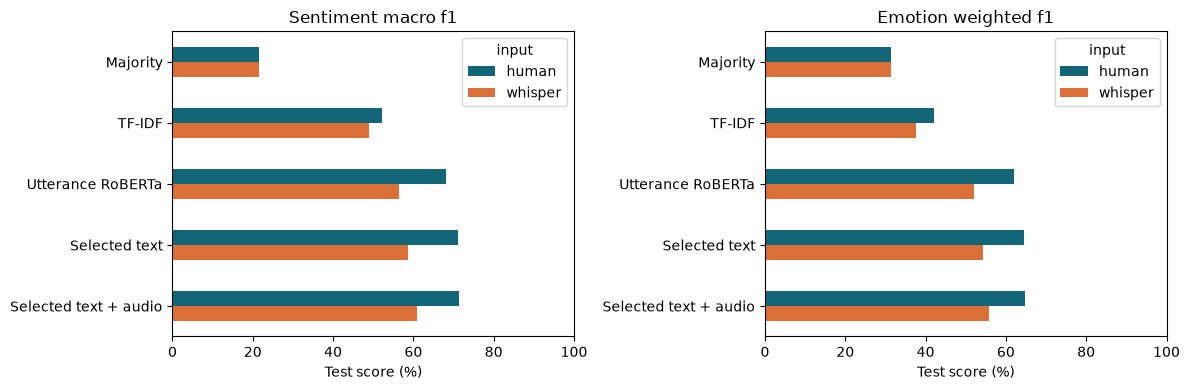

In [10]:
models = ['Majority', 'TF-IDF', 'Utterance RoBERTa', 'Selected text', 'Selected text + audio']
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, task, metric in zip(axes, ['sentiment', 'emotion'], ['macro_f1', 'weighted_f1']):
    selected = test[(test.task == task) & test.model.isin(models)]
    chart = selected.pivot(index='model', columns='input', values=metric).reindex(models)
    chart.plot.barh(ax=ax, color=['#126678', '#DA7038'])
    ax.set_title(f'{task.capitalize()} {metric.replace("_", " ")}')
    ax.set_xlim(0, 100)
    ax.set_xlabel('Test score (%)')
    ax.set_ylabel('')
    ax.invert_yaxis()
fig.tight_layout()
plt.show()

In [11]:
print('Matched checkpoint:', settings['matched_input_model'])
print(f'Whisper test word error rate: {settings["whisper_test_wer"]:.2f}%')
display(test[test.model == 'Same checkpoint'][columns].reset_index(drop=True))
classes = pd.read_csv(out / 'final_per_class.csv')
display(classes.query("model == 'Selected text + audio' and task == 'emotion'")
        [['input', 'label', 'precision', 'recall', 'f1-score', 'support']].round(3).reset_index(drop=True))

Matched checkpoint: context_mixed_roberta-large
Whisper test word error rate: 34.55%


,input,model,task,accuracy,macro_f1,weighted_f1
0,human,Same checkpoint,sentiment,72.80,71.17,72.83
1,human,Same checkpoint,emotion,64.87,48.45,64.59
2,whisper,Same checkpoint,sentiment,62.07,58.65,61.42
3,whisper,Same checkpoint,emotion,55.59,40.14,54.38


,input,label,precision,recall,f1-score,support
0,human,anger,0.559,0.496,0.525,345.0
1,human,disgust,0.346,0.132,0.191,68.0
2,human,fear,0.188,0.260,0.218,50.0
3,human,joy,0.607,0.692,0.647,402.0
4,human,neutral,0.779,0.764,0.771,1256.0
5,human,sadness,0.448,0.418,0.433,208.0
6,human,surprise,0.556,0.641,0.595,281.0
7,whisper,anger,0.526,0.354,0.423,345.0
8,whisper,disgust,0.257,0.132,0.175,68.0
9,whisper,fear,0.138,0.160,0.148,50.0


In [12]:
ablation = test[test.model.str.startswith('Mixed base,')]
display(ablation[columns].reset_index(drop=True))

,input,model,task,accuracy,macro_f1,weighted_f1
0,human,"Mixed base, target only",sentiment,70.46,68.53,70.62
1,human,"Mixed base, target only",emotion,63.26,46.21,63.39
2,human,"Mixed base, nearby turns",sentiment,69.96,68.12,70.15
3,human,"Mixed base, nearby turns",emotion,63.26,45.86,63.22
4,whisper,"Mixed base, target only",sentiment,60.65,56.95,59.94
5,whisper,"Mixed base, target only",emotion,53.68,36.63,52.57
6,whisper,"Mixed base, nearby turns",sentiment,61.19,57.76,60.61
7,whisper,"Mixed base, nearby turns",emotion,53.91,36.33,53.04


In [13]:
examples = json.loads((out / 'final_summary_examples.json').read_text(encoding='utf-8'))
for source, example in examples.items():
    print(f'{source}: test dialogue {example["dialogue"]}')
    for quote in example['quotes']:
        print(f'  {quote["speaker"]}: {quote["text"]}')
    for speaker, sequence in example['trajectories'].items():
        print(f'  {speaker} emotions: ' + ' → '.join(sequence))
    print()
trajectory = pd.read_csv(out / 'final_summary_scores.csv')
display((100 * trajectory.groupby(['input', 'method']).trajectory_similarity.mean()).round(2)
        .rename('mean ordered similarity (%)').to_frame())

human: test dialogue 4
  Monica: Oh my God!
  Phoebe: Oh no wait, oh no, the elastic on my underwear busted.
  Monica: Oh wait, Joey, you can't go like that! You stink!
  Phoebe emotions: surprise → fear
  Monica emotions: surprise → disgust
  Joey emotions: surprise → fear → neutral

whisper: test dialogue 4
  Phoebe: Oh!
  Phoebe: It kicked. I think the baby kicked.
  Monica: Oh my god.
  Phoebe emotions: surprise
  Monica emotions: surprise → disgust
  Joey emotions: surprise → fear → neutral



mean ordered similarity (%)
input   method                                       
human   baseline_emotion                        61.49
        final_emotion                           63.64
whisper baseline_emotion                        51.88
        final_emotion                           54.14